# Klasifikasi Citra Tulisan Tangan (Identifikasi Penulis) — Dataset MLA

**Alur notebook**
1. Setup & split data ← *bagian ini*
2. Ekstraksi fitur GLCM
3. LDA + GLCM
4. Gaussian Naive Bayes + GLCM
5. ResNet18
6. SqueezeNet
7. Rekap hasil

**Desain eksperimen**
- Test set **20%** dipisah paling awal (stratified per penulis, seed tetap) → hanya dipakai untuk mengisi tabel laporan.
- Sisa **80%** dibagi **5-fold stratified** → Eksperimen ke-1 s.d. 5. Tiap eksperimen: 4 fold untuk latih, 1 fold untuk validasi.
- Semua algoritma memakai pembagian data yang **sama persis** (disimpan ke CSV).

## 1. Setup & Split Data
### 1.1 Hubungkan Google Drive dan ekstrak dataset
Zip disimpan di Drive (`MyDrive/UAS_ML/dataset_clean.zip`), lalu diekstrak ke penyimpanan lokal Colab (`/content`) karena membaca ribuan file kecil langsung dari Drive sangat lambat.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

FOLDER_DRIVE = '/content/drive/MyDrive/UAS_ML'
!unzip -q -o "{FOLDER_DRIVE}/dataset_clean.zip" -d /content

Mounted at /content/drive


### 1.2 Import library dan konfigurasi
`SEED` dikunci supaya hasil split dan eksperimen bisa diulang dengan hasil yang sama.

In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold

SEED      = 42
DATA_DIR  = '/content/dataset_clean'          # hasil ekstrak zip
HASIL_DIR = f'{FOLDER_DRIVE}/hasil'           # semua hasil disimpan di Drive
os.makedirs(HASIL_DIR, exist_ok=True)

TEST_SIZE = 0.20   # porsi test set
N_FOLD    = 5      # jumlah eksperimen

### 1.3 Daftar semua gambar beserta labelnya
Label = nama folder (satu folder = satu penulis).

In [3]:
data = []
for penulis in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, penulis)
    for nama_file in sorted(os.listdir(folder)):
        data.append({'path': os.path.join(folder, nama_file), 'label': penulis})

df = pd.DataFrame(data)

# Ubah nama penulis menjadi angka 0..49 (dibutuhkan oleh model)
daftar_penulis = sorted(df['label'].unique())
df['label_id'] = df['label'].map({p: i for i, p in enumerate(daftar_penulis)})

print('Jumlah gambar :', len(df))
print('Jumlah penulis:', len(daftar_penulis))
print('Gambar per penulis: min', df['label'].value_counts().min(),
      '| maks', df['label'].value_counts().max())

Jumlah gambar : 2658
Jumlah penulis: 50
Gambar per penulis: min 50 | maks 65


### 1.4 Split: test 20% + 5-fold pada sisa 80%
Kolom `split` berisi:
- `test` → data uji akhir
- `0`–`4` → nomor fold. Pada eksperimen ke-*k*, fold *k* menjadi **validasi**, 4 fold lainnya menjadi **data latih**.

Jika file split sudah ada di Drive, file itu yang dipakai (tidak dibuat ulang), supaya pembagian data tetap sama walaupun Colab di-restart.

In [4]:
FILE_SPLIT = f'{HASIL_DIR}/split_data.csv'

if os.path.exists(FILE_SPLIT):
    df = pd.read_csv(FILE_SPLIT)
    df['path'] = df['path'].apply(lambda p: os.path.join(DATA_DIR, *p.split('/')[-2:]))
    print('Split dimuat dari Drive:', FILE_SPLIT)
else:
    # Langkah 1: pisahkan test 20% (stratified = proporsi tiap penulis sama)
    idx_sisa, idx_test = train_test_split(
        df.index, test_size=TEST_SIZE, stratify=df['label_id'], random_state=SEED)
    df.loc[idx_test, 'split'] = 'test'

    # Langkah 2: bagi sisa 80% menjadi 5 fold stratified
    df_sisa = df.loc[idx_sisa]
    skf = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=SEED)
    for nomor_fold, (_, idx_val) in enumerate(skf.split(df_sisa, df_sisa['label_id'])):
        df.loc[df_sisa.index[idx_val], 'split'] = str(nomor_fold)

    df.to_csv(FILE_SPLIT, index=False)
    print('Split baru dibuat dan disimpan:', FILE_SPLIT)

print(df['split'].value_counts().sort_index())

Split baru dibuat dan disimpan: /content/drive/MyDrive/UAS_ML/hasil/split_data.csv
split
0       426
1       425
2       425
3       425
4       425
test    532
Name: count, dtype: int64


### 1.5 Cek hasil split
Memastikan setiap penulis muncul di test dan di setiap fold, serta tidak ada gambar yang dobel.

In [5]:
tabel = pd.crosstab(df['label'], df['split'])
print('Jumlah gambar per penulis di tiap bagian (5 penulis pertama):')
display(tabel.head())

print('Penulis dengan 0 gambar di salah satu bagian:', (tabel == 0).any(axis=1).sum())
print('Gambar dobel:', df['path'].duplicated().sum())

Jumlah gambar per penulis di tiap bagian (5 penulis pertama):


split,0,1,2,3,4,test
label,,,,,,
A220199,8,8,9,8,8,10
A240008,9,9,9,9,9,11
A240029,8,8,8,8,8,10
A240037,9,9,9,9,9,11
A240089,11,11,10,10,10,13


Penulis dengan 0 gambar di salah satu bagian: 0
Gambar dobel: 0






### 1.6 Fungsi bantu: ambil data latih & validasi untuk eksperimen ke-k
Dipakai oleh semua algoritma di bagian berikutnya.

In [6]:
def ambil_split(df, fold):
    """Kembalikan (data_latih, data_validasi, data_test) untuk eksperimen ke-(fold+1)."""
    fold = str(fold)
    data_test = df[df['split'] == 'test']
    data_val  = df[df['split'] == fold]
    data_latih = df[(df['split'] != 'test') & (df['split'] != fold)]
    return data_latih, data_val, data_test

latih, val, test = ambil_split(df, 0)
print(f'Eksperimen 1 -> latih: {len(latih)} | validasi: {len(val)} | test: {len(test)}')

Eksperimen 1 -> latih: 1700 | validasi: 426 | test: 532


### 2.1 Parameter dan fungsi ekstraksi

In [7]:
import time
from PIL import Image
from skimage.feature import graycomatrix, graycoprops

TINGGI   = 128
LEVEL    = 32
JARAK    = [1, 3, 5]   # bukan 1,2,3: di sudut diagonal, jarak 2 dibulatkan jadi sama dengan jarak 1
SUDUT    = [0, np.pi/4, np.pi/2, 3*np.pi/4]
NAMA_SUDUT = ['0', '45', '90', '135']
PROPERTI = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']


def siapkan_gambar(path):
    """Grayscale -> tinggi 128 px (rasio dijaga) -> kuantisasi ke 32 level (nilai 0..31)."""
    img = Image.open(path).convert('L')
    lebar, tinggi = img.size
    lebar_baru = max(1, round(lebar * TINGGI / tinggi))
    img = img.resize((lebar_baru, TINGGI))
    return (np.array(img) // (256 // LEVEL)).astype(np.uint8)


def ekstrak_glcm(gambar):
    """Hitung GLCM lalu ambil 6 properti untuk setiap kombinasi jarak x sudut (72 fitur)."""
    glcm = graycomatrix(gambar, distances=JARAK, angles=SUDUT,
                        levels=LEVEL, symmetric=True, normed=True)
    fitur = {}
    for prop in PROPERTI:
        nilai = graycoprops(glcm, prop)          # bentuk: (jumlah jarak, jumlah sudut)
        for i, d in enumerate(JARAK):
            for j, s in enumerate(NAMA_SUDUT):
                fitur[f'{prop}_d{d}_a{s}'] = nilai[i, j]
    return fitur

### 2.2 contoh visual (untuk presentasi)

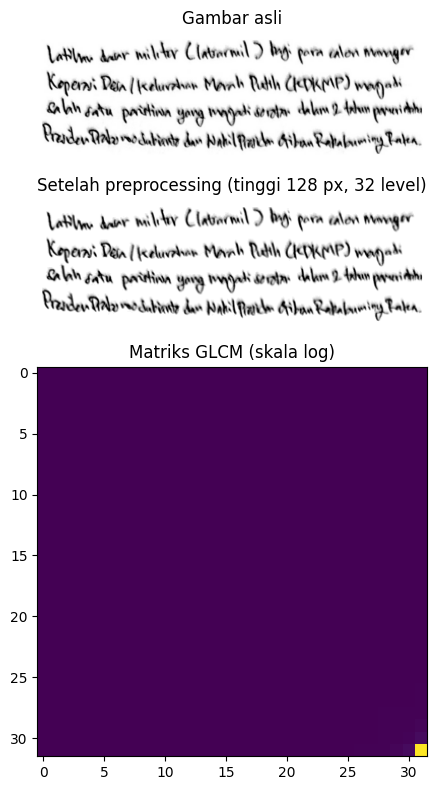

In [8]:
import matplotlib.pyplot as plt

contoh = df['path'].iloc[0]
gambar = siapkan_gambar(contoh)
glcm = graycomatrix(gambar, distances=[1], angles=[0], levels=LEVEL, symmetric=True, normed=True)

fig, ax = plt.subplots(3, 1, figsize=(10, 8), gridspec_kw={'height_ratios': [1, 1, 3]})
ax[0].imshow(Image.open(contoh), cmap='gray'); ax[0].set_title('Gambar asli')
ax[1].imshow(gambar, cmap='gray');             ax[1].set_title(f'Setelah preprocessing (tinggi {TINGGI} px, {LEVEL} level)')
ax[2].imshow(np.log1p(glcm[:, :, 0, 0]), cmap='viridis'); ax[2].set_title('Matriks GLCM (skala log)')
for a in ax[:2]: a.axis('off')
plt.tight_layout(); plt.show()

### 2.3 Ekstraksi semua gambar dan catat waktu

In [9]:
import json

FILE_FITUR = f'{HASIL_DIR}/fitur_glcm.csv'
FILE_WAKTU = f'{HASIL_DIR}/waktu_glcm.json'

if os.path.exists(FILE_FITUR):
    df_fitur = pd.read_csv(FILE_FITUR)
    waktu = json.load(open(FILE_WAKTU))
    print('Fitur dimuat dari Drive.')
else:
    daftar_fitur = []
    mulai = time.perf_counter()
    for path in df['path']:
        daftar_fitur.append(ekstrak_glcm(siapkan_gambar(path)))
    total = time.perf_counter() - mulai

    df_fitur = pd.concat([df[['path', 'label', 'label_id', 'split']].reset_index(drop=True),
                          pd.DataFrame(daftar_fitur)], axis=1)
    df_fitur.to_csv(FILE_FITUR, index=False)

    waktu = {'total_detik': total, 'per_gambar_ms': total / len(df) * 1000, 'jumlah_gambar': len(df)}
    json.dump(waktu, open(FILE_WAKTU, 'w'))

print(f"Waktu ekstraksi GLCM: {waktu['total_detik']:.2f} detik untuk {waktu['jumlah_gambar']} gambar "
      f"({waktu['per_gambar_ms']:.2f} ms per gambar)")

Waktu ekstraksi GLCM: 35.05 detik untuk 2658 gambar (13.19 ms per gambar)


### 2.4 Cek hasil fitur

In [10]:
KOLOM_FITUR = [k for k in df_fitur.columns if k.startswith(tuple(PROPERTI))]
print('Bentuk data fitur :', df_fitur[KOLOM_FITUR].shape)   # harus (2658, 72)
print('Nilai kosong (NaN):', df_fitur[KOLOM_FITUR].isna().sum().sum())
df_fitur[KOLOM_FITUR].describe().T.head(12)

Bentuk data fitur : (2658, 72)
Nilai kosong (NaN): 0


,count,mean,std,min,25%,50%,75%,max
contrast_d1_a0,2658.0,10.636085,10.262438,0.171438,4.064262,7.221240,13.654238,71.825735
contrast_d1_a45,2658.0,15.152588,13.526621,0.241261,6.057050,10.691010,19.736877,92.594396
contrast_d1_a90,2658.0,5.651732,5.268314,0.063619,2.268843,3.933508,7.046798,34.820946
contrast_d1_a135,2658.0,14.314115,12.626228,0.278340,6.033800,10.543840,18.492151,92.116776
contrast_d3_a0,2658.0,42.535938,25.909178,1.213039,23.902131,36.928901,55.865793,166.868278
contrast_d3_a45,2658.0,36.696981,24.510371,0.866614,19.127426,30.111628,48.575048,140.344324
contrast_d3_a90,2658.0,27.649765,18.338831,0.481755,14.843887,23.168996,35.457831,111.520708
contrast_d3_a135,2658.0,35.603047,23.629980,0.991129,18.709648,30.112439,47.342029,148.853258
contrast_d5_a0,2658.0,55.068075,26.799752,2.409611,35.407390,52.496902,71.487809,174.623511
contrast_d5_a45,2658.0,60.106848,29.437114,2.479975,38.986020,56.386673,77.188923,189.008151


3.1: fungsi bantu (nanti dipakai ulang untuk Gaussian NB)

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df_fitur['split'] = df_fitur['split'].astype(str)

# Fitur correlation bisa bernilai negatif, jadi tidak ikut di-log
KOLOM_LOG = [k for k in KOLOM_FITUR if not k.startswith('correlation')]


def siapkan_fitur(data, pakai_log):
    """Ambil 72 kolom fitur; jika pakai_log=True, terapkan log(1+x) pada fitur selain correlation."""
    X = data[KOLOM_FITUR].copy()
    if pakai_log:
        X[KOLOM_LOG] = np.log1p(X[KOLOM_LOG])
    return X.values


def hitung_metrik(y_asli, y_tebak):
    """Metrik macro: setiap penulis diberi bobot yang sama."""
    return {
        'Precision': precision_score(y_asli, y_tebak, average='macro', zero_division=0),
        'Recall':    recall_score(y_asli, y_tebak, average='macro', zero_division=0),
        'Akurasi':   accuracy_score(y_asli, y_tebak),
        'F1-Score':  f1_score(y_asli, y_tebak, average='macro', zero_division=0),
    }


def jalankan_eksperimen(buat_model, pakai_log):
    """Latih model di 5 fold. Kembalikan skor validasi dan skor test untuk setiap eksperimen."""
    hasil_val, hasil_test = [], []
    for fold in range(N_FOLD):
        latih, val, test = ambil_split(df_fitur, fold)

        # Standarisasi: scaler HANYA belajar dari data latih (mencegah kebocoran data)
        scaler = StandardScaler().fit(siapkan_fitur(latih, pakai_log))
        X_latih = scaler.transform(siapkan_fitur(latih, pakai_log))
        X_val   = scaler.transform(siapkan_fitur(val, pakai_log))
        X_test  = scaler.transform(siapkan_fitur(test, pakai_log))

        model = buat_model()
        mulai = time.perf_counter()
        model.fit(X_latih, latih['label_id'])
        waktu_latih = time.perf_counter() - mulai

        hasil_val.append(hitung_metrik(val['label_id'], model.predict(X_val)))
        hasil_test.append({**hitung_metrik(test['label_id'], model.predict(X_test)),
                           'Waktu Pelatihan (detik)': waktu_latih})
    return pd.DataFrame(hasil_val), pd.DataFrame(hasil_test)


def tabel_laporan(hasil_test):
    """Format sesuai tabel laporan: Eksperimen 1-5 + baris Rata-Rata."""
    tabel = hasil_test.copy()
    tabel.index = [f'{i + 1}' for i in range(len(tabel))]
    tabel.loc['Rata-Rata'] = tabel.mean()
    tabel.index.name = 'Eksperimen ke'
    return tabel.round(4)

Sel 3.2: tentukan pakai log atau tidak (berdasarkan skor validasi)

In [12]:
buat_lda = lambda: LinearDiscriminantAnalysis()

val_tanpa_log, test_tanpa_log = jalankan_eksperimen(buat_lda, pakai_log=False)
val_log,       test_log       = jalankan_eksperimen(buat_lda, pakai_log=True)

perbandingan = pd.DataFrame({
    'Tanpa log': val_tanpa_log.mean(),
    'Dengan log': val_log.mean(),
}).round(4)
print('Rata-rata skor VALIDASI LDA (5 fold):')
display(perbandingan)

lda_pakai_log = val_log['F1-Score'].mean() > val_tanpa_log['F1-Score'].mean()
print('Dipilih:', 'DENGAN log' if lda_pakai_log else 'TANPA log', '(berdasarkan F1-Score validasi)')

Rata-rata skor VALIDASI LDA (5 fold):


,Tanpa log,Dengan log
Precision,0.8953,0.9059
Recall,0.8758,0.8893
Akurasi,0.8777,0.8913
F1-Score,0.8758,0.8884


Dipilih: DENGAN log (berdasarkan F1-Score validasi)


Sel 3.3: tabel laporan (skor di test set)

In [13]:
hasil_lda = tabel_laporan(test_log if lda_pakai_log else test_tanpa_log)
hasil_lda.to_csv(f'{HASIL_DIR}/hasil_lda.csv')

print(f"Algoritma 1: LDA + GLCM ({'dengan' if lda_pakai_log else 'tanpa'} log) — skor pada TEST SET")
display(hasil_lda)

Algoritma 1: LDA + GLCM (dengan log) — skor pada TEST SET


,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (detik)
Eksperimen ke,,,,,
1,0.9161,0.8970,0.8985,0.8979,0.1627
2,0.9116,0.8957,0.8966,0.8953,0.0933
3,0.9085,0.8893,0.8910,0.8890,0.0229
4,0.9074,0.8918,0.8929,0.8909,0.0505
5,0.9107,0.8913,0.8929,0.8918,0.0283
Rata-Rata,0.9109,0.8930,0.8944,0.8930,0.0715


Sel 4.1: tentukan pakai log atau tidak (berdasarkan skor validasi)

In [14]:
from sklearn.naive_bayes import GaussianNB

buat_nb = lambda: GaussianNB()

nb_val_tanpa_log, nb_test_tanpa_log = jalankan_eksperimen(buat_nb, pakai_log=False)
nb_val_log,       nb_test_log       = jalankan_eksperimen(buat_nb, pakai_log=True)

perbandingan_nb = pd.DataFrame({
    'Tanpa log': nb_val_tanpa_log.mean(),
    'Dengan log': nb_val_log.mean(),
}).round(4)
print('Rata-rata skor VALIDASI Gaussian NB (5 fold):')
display(perbandingan_nb)

nb_pakai_log = nb_val_log['F1-Score'].mean() > nb_val_tanpa_log['F1-Score'].mean()
print('Dipilih:', 'DENGAN log' if nb_pakai_log else 'TANPA log', '(berdasarkan F1-Score validasi)')

Rata-rata skor VALIDASI Gaussian NB (5 fold):


,Tanpa log,Dengan log
Precision,0.2991,0.2820
Recall,0.3115,0.3063
Akurasi,0.3123,0.3071
F1-Score,0.2743,0.2678


Dipilih: TANPA log (berdasarkan F1-Score validasi)


Sel 4.2: tabel laporan (skor di test set)

In [15]:
hasil_nb = tabel_laporan(nb_test_log if nb_pakai_log else nb_test_tanpa_log)
hasil_nb.to_csv(f'{HASIL_DIR}/hasil_gaussian_nb.csv')

print(f"Algoritma 2: Gaussian NB + GLCM ({'dengan' if nb_pakai_log else 'tanpa'} log) — skor pada TEST SET")
display(hasil_nb)

Algoritma 2: Gaussian NB + GLCM (tanpa log) — skor pada TEST SET


,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (detik)
Eksperimen ke,,,,,
1,0.3495,0.3438,0.3459,0.3137,0.0046
2,0.3413,0.3294,0.3308,0.2920,0.0037
3,0.3539,0.3301,0.3327,0.2938,0.0036
4,0.3274,0.3345,0.3365,0.2998,0.0038
5,0.3298,0.3221,0.3233,0.2921,0.0043
Rata-Rata,0.3404,0.3320,0.3338,0.2983,0.0040


Sel 5.1: setting

In [16]:
import shutil
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)            # harus 'cuda'. Jika 'cpu': Runtime -> Change runtime type -> T4 GPU

INPUT_TINGGI, INPUT_LEBAR = 128, 1024
BATCH_SIZE   = 32
LR           = 1e-4
MAX_EPOCH    = 30
PATIENCE     = 5        # berhenti jika F1 validasi tidak naik selama 5 epoch
PAKAI_AUGMENTASI = False
JUMLAH_KELAS = df['label_id'].nunique()

# Normalisasi standar ImageNet (karena memakai bobot pretrained ImageNet)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

Device: cuda


Sel 5.2: siapkan gambar dan dataset

2658 gambar dimuat ke RAM dalam 11.0 detik


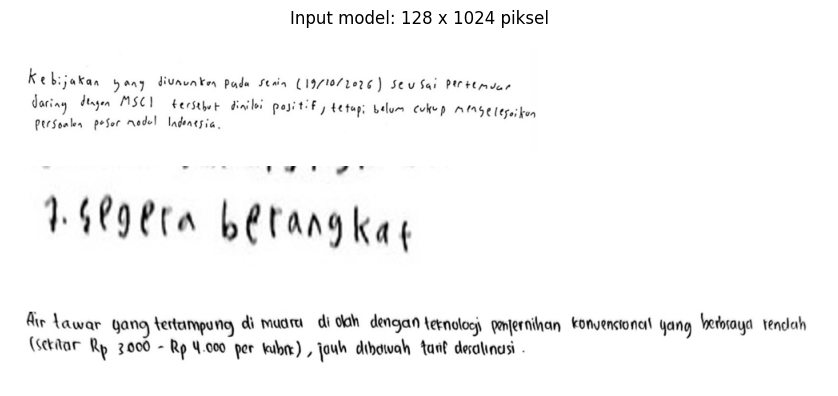

In [17]:
def ubah_ukuran_dan_pad(img):
    """Tinggi jadi 128 px (rasio dijaga). Jika masih lebih lebar dari 1024, diperkecil agar muat.
    Sisa ruang diisi putih -> semua gambar berukuran 128 x 1024 tanpa tulisan menjadi gepeng."""
    lebar, tinggi = img.size
    skala = min(INPUT_TINGGI / tinggi, INPUT_LEBAR / lebar)
    lebar_baru, tinggi_baru = max(1, round(lebar * skala)), max(1, round(tinggi * skala))
    img = img.resize((lebar_baru, tinggi_baru))
    kanvas = Image.new('L', (INPUT_LEBAR, INPUT_TINGGI), 255)
    kanvas.paste(img, (0, (INPUT_TINGGI - tinggi_baru) // 2))
    return kanvas


# Simpan semua gambar yang sudah di-resize ke RAM sekali saja (sekitar 350 MB),
# supaya tiap epoch tidak perlu membaca & me-resize ulang dari file.
mulai = time.perf_counter()
CACHE = {p: np.array(ubah_ukuran_dan_pad(Image.open(p).convert('L'))) for p in df['path']}
print(f'{len(CACHE)} gambar dimuat ke RAM dalam {time.perf_counter() - mulai:.1f} detik')

transform_dasar = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),   # 1 channel -> 3 channel (format model pretrained)
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
transform_augmentasi = transforms.Compose([         # hanya dipakai jika PAKAI_AUGMENTASI = True
    transforms.RandomAffine(degrees=3, translate=(0.02, 0.05), scale=(0.95, 1.05), fill=255),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transform_dasar,
])


class DatasetTulisan(Dataset):
    def __init__(self, data, transform):
        self.path = data['path'].tolist()
        self.label = data['label_id'].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.path)

    def __getitem__(self, i):
        img = Image.fromarray(CACHE[self.path[i]])
        return self.transform(img), self.label[i]


# Contoh: tampilkan 3 gambar input model (untuk presentasi)
fig, ax = plt.subplots(3, 1, figsize=(12, 4))
for a, p in zip(ax, df['path'].sample(3, random_state=SEED)):
    a.imshow(CACHE[p], cmap='gray'); a.axis('off')
plt.suptitle(f'Input model: {INPUT_TINGGI} x {INPUT_LEBAR} piksel'); plt.tight_layout(); plt.show()

Sel 5.3: model, training satu fold, dan fungsi bantu (nanti dipakai ulang untuk SqueezeNet)

In [18]:
def buat_resnet18():
    """ResNet18 pretrained ImageNet; layer terakhir (1000 kelas) diganti menjadi 50 kelas penulis."""
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, JUMLAH_KELAS)
    return model


def evaluasi(model, loader, loss_fn):
    """Kembalikan (rata-rata loss, label asli, label tebakan)."""
    model.eval()
    total_loss, asli, tebak = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            keluaran = model(x)
            total_loss += loss_fn(keluaran, y).item() * len(y)
            asli += y.tolist()
            tebak += keluaran.argmax(dim=1).tolist()
    return total_loss / len(asli), asli, tebak


def latih_satu_fold(buat_model, nama_model, fold):
    latih, val, test = ambil_split(df, fold)
    tf_latih = transform_augmentasi if PAKAI_AUGMENTASI else transform_dasar
    loader_latih = DataLoader(DatasetTulisan(latih, tf_latih), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    loader_val   = DataLoader(DatasetTulisan(val, transform_dasar), batch_size=BATCH_SIZE, num_workers=2)
    loader_test  = DataLoader(DatasetTulisan(test, transform_dasar), batch_size=BATCH_SIZE, num_workers=2)

    torch.manual_seed(SEED + fold)
    model = buat_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()

    file_bobot_lokal = f'/content/{nama_model}_fold{fold + 1}.pt'
    riwayat, f1_terbaik, epoch_terbaik, tanpa_naik = [], -1, 0, 0

    mulai = time.perf_counter()
    for epoch in range(1, MAX_EPOCH + 1):
        # --- latih 1 epoch ---
        model.train()
        total_loss = 0.0
        for x, y in loader_latih:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)

        # --- cek validasi ---
        loss_val, asli, tebak = evaluasi(model, loader_val, loss_fn)
        f1_val = hitung_metrik(asli, tebak)['F1-Score']
        riwayat.append({'epoch': epoch, 'loss_latih': total_loss / len(latih),
                        'loss_val': loss_val, 'f1_val': f1_val})
        print(f'Epoch {epoch:2d} | loss latih {riwayat[-1]["loss_latih"]:.4f} | '
              f'loss val {loss_val:.4f} | F1 val {f1_val:.4f}')

        # --- early stopping: simpan bobot terbaik ---
        if f1_val > f1_terbaik:
            f1_terbaik, epoch_terbaik, tanpa_naik = f1_val, epoch, 0
            torch.save(model.state_dict(), file_bobot_lokal)
        else:
            tanpa_naik += 1
            if tanpa_naik >= PATIENCE:
                print(f'Early stopping: F1 validasi tidak naik selama {PATIENCE} epoch')
                break
    waktu_latih = time.perf_counter() - mulai

    # Uji di TEST SET memakai bobot dari epoch terbaik
    model.load_state_dict(torch.load(file_bobot_lokal))
    _, asli, tebak = evaluasi(model, loader_test, loss_fn)
    shutil.copy(file_bobot_lokal, f'{HASIL_DIR}/{nama_model}_fold{fold + 1}.pt')   # simpan ke Drive

    hasil = {'fold': fold + 1, **hitung_metrik(asli, tebak),
             'Waktu Pelatihan (detik)': waktu_latih, 'Epoch terbaik': epoch_terbaik}
    return hasil, pd.DataFrame(riwayat)


def jalankan_dl(buat_model, nama_model, daftar_fold):
    """Latih fold-fold yang diminta. Fold yang hasilnya sudah ada di Drive dilewati (aman jika Colab putus)."""
    file_hasil = f'{HASIL_DIR}/hasil_{nama_model}_per_fold.csv'
    semua = pd.read_csv(file_hasil) if os.path.exists(file_hasil) else pd.DataFrame()
    for fold in daftar_fold:
        if not semua.empty and (semua['fold'] == fold + 1).any():
            print(f'Fold {fold + 1} sudah ada di Drive, dilewati.')
            continue
        print(f'\n===== {nama_model} - Eksperimen {fold + 1} =====')
        hasil, riwayat = latih_satu_fold(buat_model, nama_model, fold)
        riwayat.to_csv(f'{HASIL_DIR}/riwayat_{nama_model}_fold{fold + 1}.csv', index=False)
        semua = pd.concat([semua, pd.DataFrame([hasil])], ignore_index=True)
        semua.to_csv(file_hasil, index=False)
    return semua.sort_values('fold').reset_index(drop=True)


def plot_kurva(nama_model, fold):
    r = pd.read_csv(f'{HASIL_DIR}/riwayat_{nama_model}_fold{fold + 1}.csv')
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(r['epoch'], r['loss_latih'], label='Loss latih')
    ax[0].plot(r['epoch'], r['loss_val'], label='Loss validasi')
    ax[0].set_xlabel('Epoch'); ax[0].set_title('Loss'); ax[0].legend()
    ax[1].plot(r['epoch'], r['f1_val'], color='green')
    ax[1].set_xlabel('Epoch'); ax[1].set_title('F1-Score validasi')
    plt.suptitle(f'{nama_model} - Eksperimen {fold + 1}'); plt.tight_layout(); plt.show()

Sel 5.4: jalankan fold 1 saja dulu, lalu lihat kurvanya


===== resnet18 - Eksperimen 1 =====
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 126MB/s]


Epoch  1 | loss latih 2.3443 | loss val 1.2205 | F1 val 0.8094
Epoch  2 | loss latih 0.6927 | loss val 0.4723 | F1 val 0.9329
Epoch  3 | loss latih 0.2948 | loss val 0.2439 | F1 val 0.9662
Epoch  4 | loss latih 0.1577 | loss val 0.1782 | F1 val 0.9692
Epoch  5 | loss latih 0.1152 | loss val 0.1632 | F1 val 0.9786
Epoch  6 | loss latih 0.0922 | loss val 0.1197 | F1 val 0.9740
Epoch  7 | loss latih 0.0573 | loss val 0.1172 | F1 val 0.9788
Epoch  8 | loss latih 0.0453 | loss val 0.0998 | F1 val 0.9810
Epoch  9 | loss latih 0.0496 | loss val 0.1278 | F1 val 0.9681
Epoch 10 | loss latih 0.0358 | loss val 0.0765 | F1 val 0.9883
Epoch 11 | loss latih 0.0220 | loss val 0.0793 | F1 val 0.9808
Epoch 12 | loss latih 0.0163 | loss val 0.0680 | F1 val 0.9909
Epoch 13 | loss latih 0.0270 | loss val 0.1071 | F1 val 0.9677
Epoch 14 | loss latih 0.0185 | loss val 0.0682 | F1 val 0.9862
Epoch 15 | loss latih 0.0267 | loss val 0.0673 | F1 val 0.9859
Epoch 16 | loss latih 0.0204 | loss val 0.0672 | F1 val

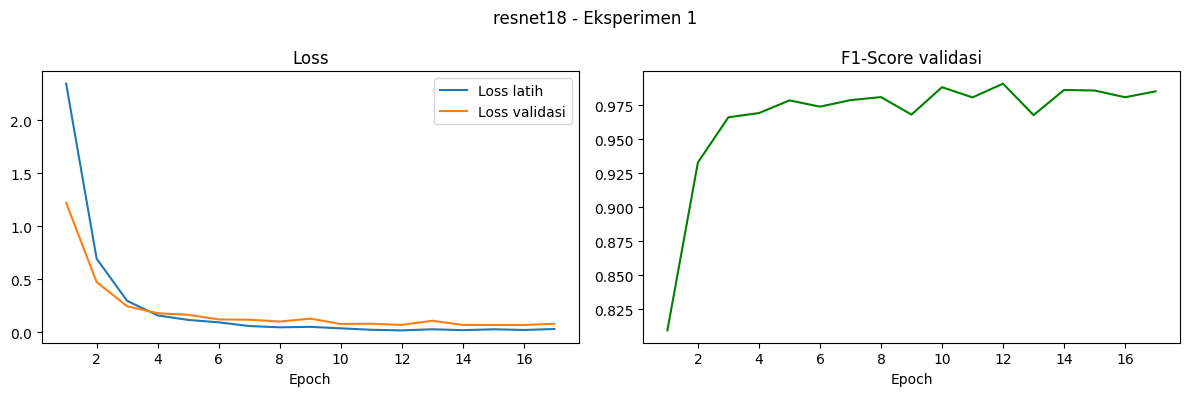

,fold,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (detik),Epoch terbaik
0,1,0.983415,0.980848,0.981203,0.98079,288.402664,12


In [19]:
hasil_resnet = jalankan_dl(buat_resnet18, 'resnet18', daftar_fold=[0])
plot_kurva('resnet18', fold=0)
display(hasil_resnet)

Sel 5.5: jalankan semua fold (fold 1 otomatis dilewati karena sudah ada di Drive)

In [20]:
hasil_resnet = jalankan_dl(buat_resnet18, 'resnet18', daftar_fold=range(N_FOLD))

Fold 1 sudah ada di Drive, dilewati.

===== resnet18 - Eksperimen 2 =====
Epoch  1 | loss latih 2.3252 | loss val 1.1749 | F1 val 0.8259
Epoch  2 | loss latih 0.6887 | loss val 0.4840 | F1 val 0.9297
Epoch  3 | loss latih 0.3107 | loss val 0.2094 | F1 val 0.9734
Epoch  4 | loss latih 0.1629 | loss val 0.1519 | F1 val 0.9809
Epoch  5 | loss latih 0.0843 | loss val 0.1626 | F1 val 0.9759
Epoch  6 | loss latih 0.0652 | loss val 0.1380 | F1 val 0.9790
Epoch  7 | loss latih 0.0419 | loss val 0.1118 | F1 val 0.9853
Epoch  8 | loss latih 0.0453 | loss val 0.0874 | F1 val 0.9904
Epoch  9 | loss latih 0.0399 | loss val 0.0833 | F1 val 0.9904
Epoch 10 | loss latih 0.0284 | loss val 0.0881 | F1 val 0.9901
Epoch 11 | loss latih 0.0636 | loss val 0.0972 | F1 val 0.9809
Epoch 12 | loss latih 0.0348 | loss val 0.0680 | F1 val 0.9904
Epoch 13 | loss latih 0.0305 | loss val 0.1275 | F1 val 0.9767
Early stopping: F1 validasi tidak naik selama 5 epoch

===== resnet18 - Eksperimen 3 =====
Epoch  1 | loss 

Sel 5.6: tabel laporan

In [21]:
tabel_resnet = tabel_laporan(hasil_resnet[['Precision', 'Recall', 'Akurasi', 'F1-Score', 'Waktu Pelatihan (detik)']])
tabel_resnet.to_csv(f'{HASIL_DIR}/hasil_resnet18.csv')

print('Arsitektur DL 1: ResNet18 — skor pada TEST SET')
display(tabel_resnet)
print('Epoch terbaik per eksperimen:', hasil_resnet['Epoch terbaik'].tolist())

Arsitektur DL 1: ResNet18 — skor pada TEST SET


,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (detik)
Eksperimen ke,,,,,
1,0.9834,0.9808,0.9812,0.9808,288.4027
2,0.9781,0.9752,0.9756,0.9755,225.3271
3,0.9792,0.9777,0.9774,0.9774,288.8361
4,0.9847,0.9832,0.9831,0.9832,405.9425
5,0.9877,0.9865,0.9868,0.9866,371.7531
Rata-Rata,0.9826,0.9807,0.9808,0.9807,316.0523


Epoch terbaik per eksperimen: [12, 8, 12, 19, 17]


Sel 6.1: model

In [22]:
def buat_squeezenet():
    """SqueezeNet 1.1 pretrained ImageNet; konvolusi 1x1 terakhir (1000 kelas) diganti menjadi 50 kelas."""
    model = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.IMAGENET1K_V1)
    model.classifier[1] = nn.Conv2d(512, JUMLAH_KELAS, kernel_size=1)
    return model

Sel 6.2: fold 1 dulu, lalu cek kurvanya


===== squeezenet - Eksperimen 1 =====
Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 62.0MB/s]


Epoch  1 | loss latih 3.8108 | loss val 3.5261 | F1 val 0.1341
Epoch  2 | loss latih 3.0839 | loss val 2.5118 | F1 val 0.2993
Epoch  3 | loss latih 1.9433 | loss val 1.4065 | F1 val 0.5430
Epoch  4 | loss latih 1.0362 | loss val 1.0865 | F1 val 0.6803
Epoch  5 | loss latih 0.6894 | loss val 0.7029 | F1 val 0.8033
Epoch  6 | loss latih 0.4888 | loss val 0.4771 | F1 val 0.8645
Epoch  7 | loss latih 0.3736 | loss val 0.4771 | F1 val 0.8530
Epoch  8 | loss latih 0.2984 | loss val 0.3237 | F1 val 0.9061
Epoch  9 | loss latih 0.2511 | loss val 0.3920 | F1 val 0.8873
Epoch 10 | loss latih 0.2233 | loss val 0.3165 | F1 val 0.8995
Epoch 11 | loss latih 0.2240 | loss val 0.6022 | F1 val 0.8332
Epoch 12 | loss latih 0.2831 | loss val 0.2044 | F1 val 0.9556
Epoch 13 | loss latih 0.1084 | loss val 0.1826 | F1 val 0.9544
Epoch 14 | loss latih 0.0874 | loss val 0.2617 | F1 val 0.9312
Epoch 15 | loss latih 0.0674 | loss val 0.2230 | F1 val 0.9345
Epoch 16 | loss latih 0.1112 | loss val 0.2481 | F1 val

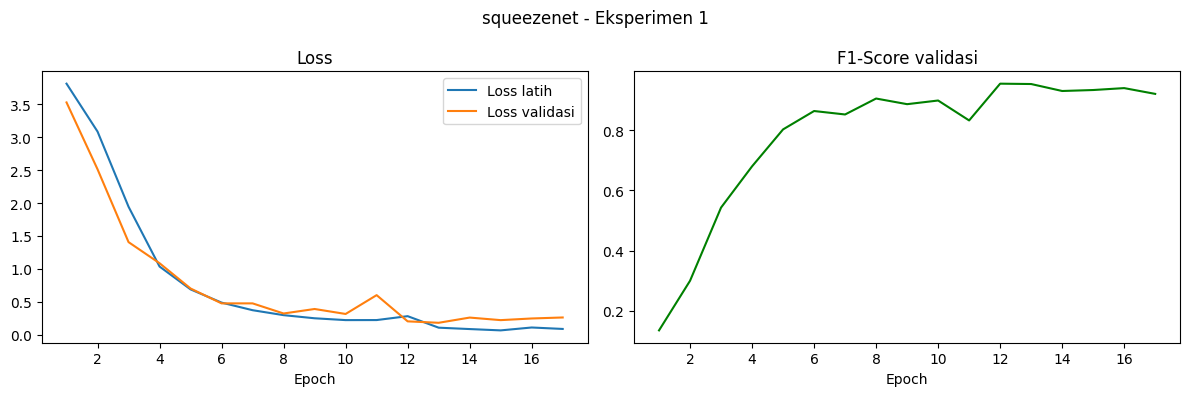

,fold,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (detik),Epoch terbaik
0,1,0.941208,0.930923,0.930451,0.929774,198.203193,12


In [23]:
hasil_squeeze = jalankan_dl(buat_squeezenet, 'squeezenet', daftar_fold=[0])
plot_kurva('squeezenet', fold=0)
display(hasil_squeeze)

Sel 6.3: lanjutkan semua fold (fold 1 otomatis dilewati)

In [24]:
hasil_squeeze = jalankan_dl(buat_squeezenet, 'squeezenet', daftar_fold=range(N_FOLD))

Fold 1 sudah ada di Drive, dilewati.

===== squeezenet - Eksperimen 2 =====
Epoch  1 | loss latih 3.7735 | loss val 3.2933 | F1 val 0.1023
Epoch  2 | loss latih 2.5940 | loss val 1.7459 | F1 val 0.5005
Epoch  3 | loss latih 1.4173 | loss val 0.8906 | F1 val 0.7158
Epoch  4 | loss latih 0.7659 | loss val 0.8494 | F1 val 0.7518
Epoch  5 | loss latih 0.5005 | loss val 0.4657 | F1 val 0.8451
Epoch  6 | loss latih 0.4115 | loss val 0.4010 | F1 val 0.8798
Epoch  7 | loss latih 0.2909 | loss val 0.3461 | F1 val 0.8998
Epoch  8 | loss latih 0.3269 | loss val 0.2516 | F1 val 0.9377
Epoch  9 | loss latih 0.2104 | loss val 0.2225 | F1 val 0.9340
Epoch 10 | loss latih 0.1895 | loss val 0.3376 | F1 val 0.8893
Epoch 11 | loss latih 0.1916 | loss val 0.3105 | F1 val 0.9028
Epoch 12 | loss latih 0.1570 | loss val 0.2149 | F1 val 0.9358
Epoch 13 | loss latih 0.1142 | loss val 0.2150 | F1 val 0.9377
Epoch 14 | loss latih 0.0542 | loss val 0.2033 | F1 val 0.9513
Epoch 15 | loss latih 0.0661 | loss val 0.

Sel 6.4: tabel laporan

In [25]:
tabel_squeeze = tabel_laporan(hasil_squeeze[['Precision', 'Recall', 'Akurasi', 'F1-Score', 'Waktu Pelatihan (detik)']])
tabel_squeeze.to_csv(f'{HASIL_DIR}/hasil_squeezenet.csv')

print('Arsitektur DL 2: SqueezeNet 1.1 — skor pada TEST SET')
display(tabel_squeeze)
print('Epoch terbaik per eksperimen:', hasil_squeeze['Epoch terbaik'].tolist())

Arsitektur DL 2: SqueezeNet 1.1 — skor pada TEST SET


,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (detik)
Eksperimen ke,,,,,
1,0.9412,0.9309,0.9305,0.9298,198.2032
2,0.9598,0.9557,0.9568,0.9548,249.6555
3,0.9570,0.9537,0.9530,0.9527,290.4970
4,0.9604,0.9569,0.9568,0.9566,323.7574
5,0.9190,0.9023,0.9023,0.9016,184.9605
Rata-Rata,0.9475,0.9399,0.9398,0.9391,249.4147


Epoch terbaik per eksperimen: [12, 15, 20, 23, 11]


In [26]:
daftar_hasil = {
    'LDA + GLCM':         'hasil_lda.csv',
    'Gaussian NB + GLCM': 'hasil_gaussian_nb.csv',
    'ResNet18':           'hasil_resnet18.csv',
    'SqueezeNet 1.1':     'hasil_squeezenet.csv',
}
rekap = pd.DataFrame({nama: pd.read_csv(f'{HASIL_DIR}/{file}', index_col=0).loc['Rata-Rata']
                      for nama, file in daftar_hasil.items()}).T
rekap.columns = ['Rata-Rata ' + k for k in rekap.columns]
rekap.index.name = 'Nama Algoritma'
rekap.to_csv(f'{HASIL_DIR}/rekap_hasil.csv')

print(f"Waktu ekstraksi GLCM: {waktu['total_detik']:.2f} detik ({waktu['per_gambar_ms']:.2f} ms per gambar)")
display(rekap.round(4))
print('Model terbaik (F1-Score tertinggi):', rekap['Rata-Rata F1-Score'].idxmax())

Waktu ekstraksi GLCM: 35.05 detik (13.19 ms per gambar)


,Rata-Rata Precision,Rata-Rata Recall,Rata-Rata Akurasi,Rata-Rata F1-Score,Rata-Rata Waktu Pelatihan (detik)
Nama Algoritma,,,,,
LDA + GLCM,0.9109,0.8930,0.8944,0.8930,0.0715
Gaussian NB + GLCM,0.3404,0.3320,0.3338,0.2983,0.0040
ResNet18,0.9826,0.9807,0.9808,0.9807,316.0523
SqueezeNet 1.1,0.9475,0.9399,0.9398,0.9391,249.4147


Model terbaik (F1-Score tertinggi): ResNet18


In [28]:
_, _, test = ambil_split(df, 0)
loader_test = DataLoader(DatasetTulisan(test, transform_dasar), batch_size=BATCH_SIZE, num_workers=2)
loss_fn = nn.CrossEntropyLoss()

semua_prediksi = []
for fold in range(N_FOLD):
    model = buat_resnet18().to(DEVICE)
    model.load_state_dict(torch.load(f'{HASIL_DIR}/resnet18_fold{fold + 1}.pt', map_location=DEVICE))
    _, asli, tebak = evaluasi(model, loader_test, loss_fn)
    semua_prediksi.append(pd.DataFrame({'path': test['path'].values, 'asli': asli,
                                        'tebak': tebak, 'model': fold + 1}))
prediksi = pd.concat(semua_prediksi, ignore_index=True)

# Cek: akurasi tiap model harus sama dengan tabel ResNet18 sebelumnya
print('Akurasi per model:', [round((d['asli'] == d['tebak']).mean(), 4) for _, d in prediksi.groupby('model')])

Akurasi per model: [np.float64(0.9812), np.float64(0.9756), np.float64(0.9774), np.float64(0.9831), np.float64(0.9868)]


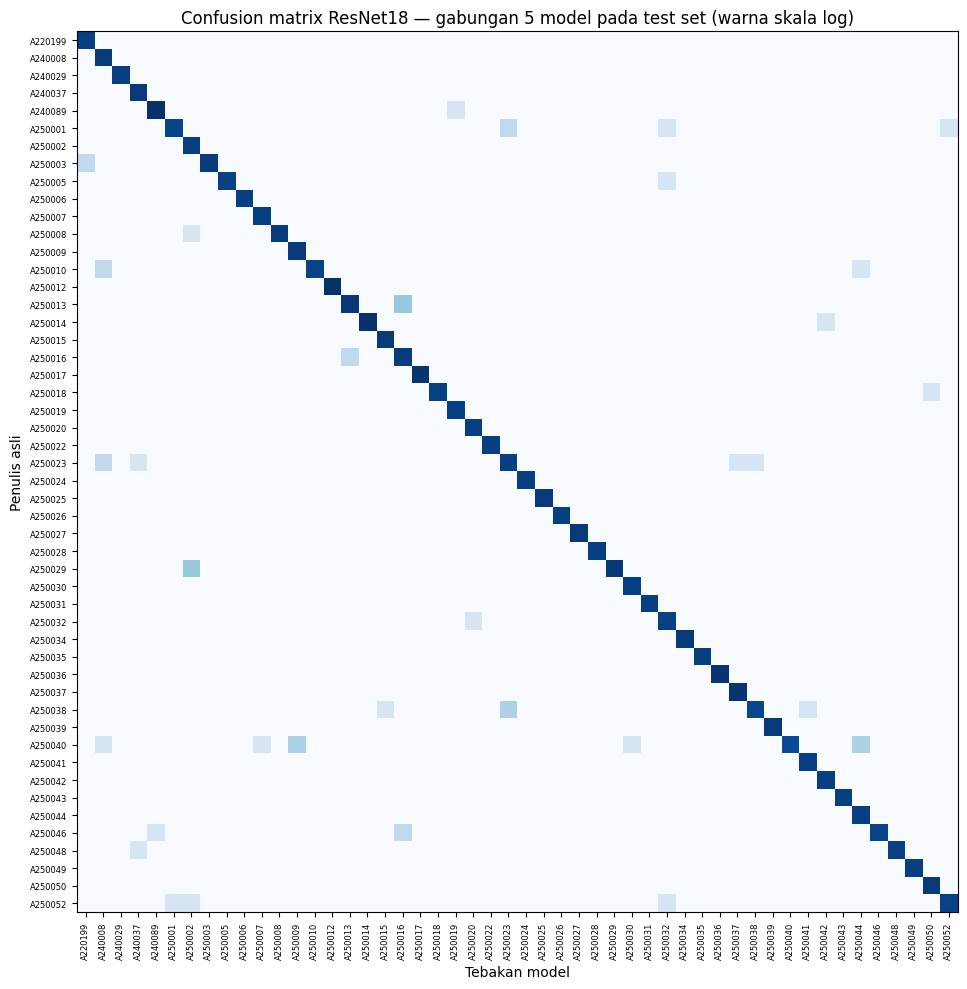

In [29]:
from sklearn.metrics import confusion_matrix

NAMA_PENULIS = df.drop_duplicates('label_id').sort_values('label_id')['label'].tolist()

cm = confusion_matrix(prediksi['asli'], prediksi['tebak'], labels=range(JUMLAH_KELAS))

fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(np.log1p(cm), cmap='Blues')
ax.set_xticks(range(JUMLAH_KELAS)); ax.set_xticklabels(NAMA_PENULIS, rotation=90, fontsize=6)
ax.set_yticks(range(JUMLAH_KELAS)); ax.set_yticklabels(NAMA_PENULIS, fontsize=6)
ax.set_xlabel('Tebakan model'); ax.set_ylabel('Penulis asli')
ax.set_title('Confusion matrix ResNet18 — gabungan 5 model pada test set (warna skala log)')
plt.tight_layout(); plt.show()

In [30]:
# Recall per penulis: dari semua gambar milik penulis ini, berapa persen yang ditebak benar
recall_per_penulis = pd.DataFrame({
    'Penulis': NAMA_PENULIS,
    'Gambar test x 5 model': cm.sum(axis=1),
    'Benar': np.diag(cm),
})
recall_per_penulis['Recall'] = (recall_per_penulis['Benar'] / recall_per_penulis['Gambar test x 5 model']).round(3)
print('5 penulis yang paling sulit dikenali:')
display(recall_per_penulis.sort_values('Recall').head(5))

# Pasangan penulis yang paling sering tertukar
salah = cm.copy()
np.fill_diagonal(salah, 0)
pasangan = [(NAMA_PENULIS[i], NAMA_PENULIS[j], salah[i, j])
            for i, j in zip(*np.nonzero(salah))]
pasangan = pd.DataFrame(pasangan, columns=['Penulis asli', 'Ditebak sebagai', 'Berapa kali'])
print(f'Total tebakan salah: {salah.sum()} dari {cm.sum()}')
print('10 pasangan yang paling sering tertukar:')
display(pasangan.sort_values('Berapa kali', ascending=False).head(10))

5 penulis yang paling sulit dikenali:


,Penulis,Gambar test x 5 model,Benar,Recall
40,A250040,50,41,0.820
38,A250038,50,45,0.900
24,A250023,55,50,0.909
5,A250001,50,46,0.920
30,A250029,60,56,0.933


Total tebakan salah: 51 dari 2660
10 pasangan yang paling sering tertukar:


,Penulis asli,Ditebak sebagai,Berapa kali
9,A250013,A250016,4
17,A250029,A250002,4
26,A250040,A250044,3
20,A250038,A250023,3
24,A250040,A250009,3
11,A250016,A250013,2
1,A250001,A250023,2
7,A250010,A240008,2
4,A250003,A220199,2
28,A250046,A250016,2


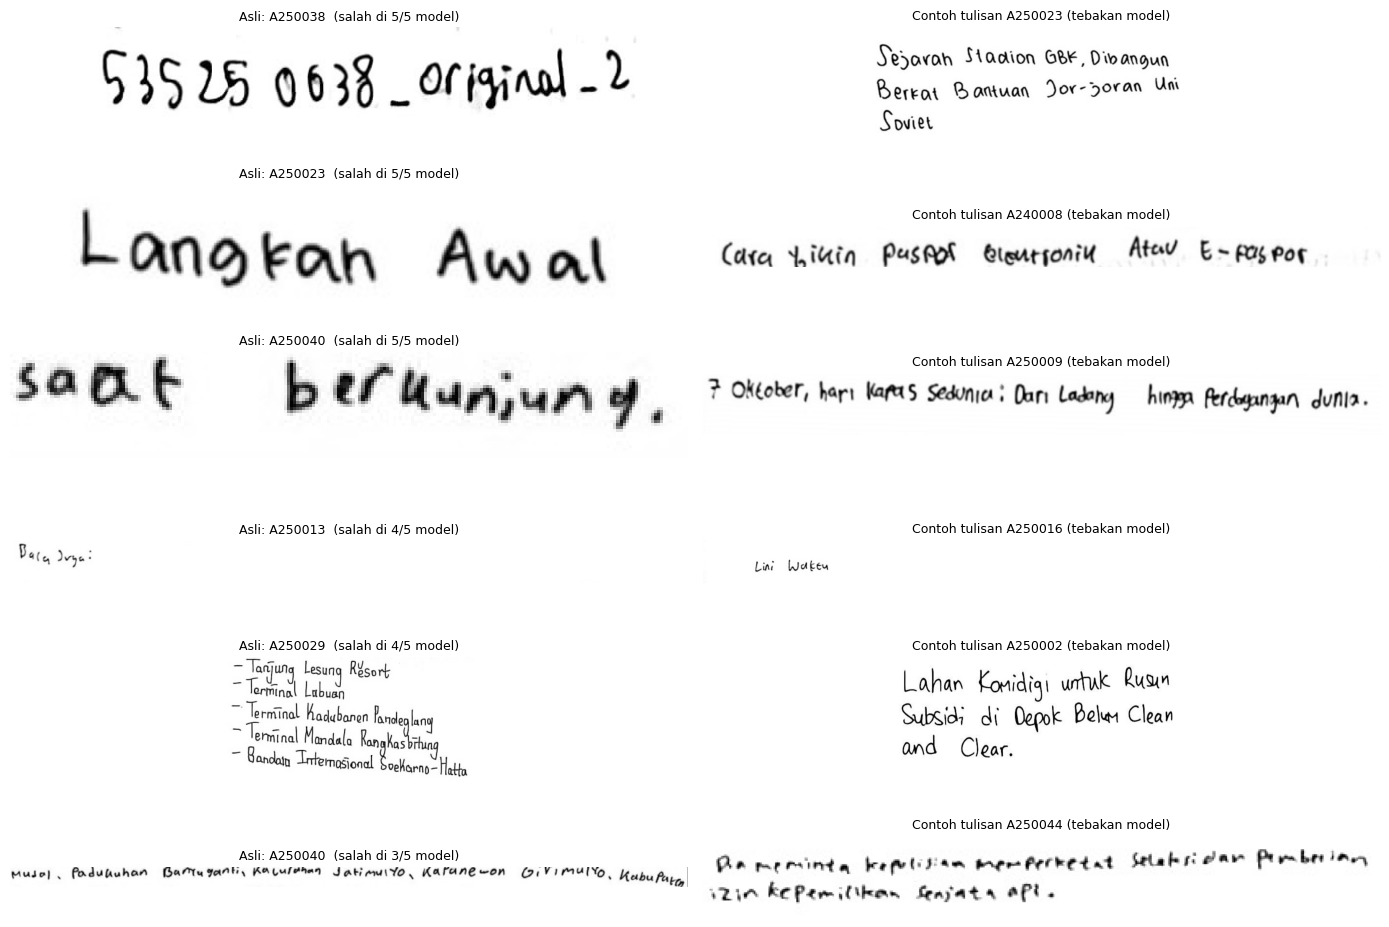

In [31]:
# Gambar yang salah ditebak oleh banyak model sekaligus = kesalahan yang konsisten (bukan kebetulan)
kesalahan = (prediksi[prediksi['asli'] != prediksi['tebak']]
             .groupby('path')
             .agg(asli=('asli', 'first'), tebak=('tebak', lambda t: t.mode()[0]), jumlah_model=('model', 'count'))
             .sort_values('jumlah_model', ascending=False)
             .head(6))

data_latih_semua = df[df['split'] != 'test']
fig, ax = plt.subplots(len(kesalahan), 2, figsize=(14, 1.6 * len(kesalahan)), squeeze=False)
for baris, (path, r) in zip(ax, kesalahan.iterrows()):
    contoh_tebakan = data_latih_semua[data_latih_semua['label_id'] == r['tebak']]['path'].iloc[0]
    baris[0].imshow(Image.open(path).convert('L'), cmap='gray')
    baris[0].set_title(f"Asli: {NAMA_PENULIS[r['asli']]}  (salah di {r['jumlah_model']}/5 model)", fontsize=9)
    baris[1].imshow(Image.open(contoh_tebakan).convert('L'), cmap='gray')
    baris[1].set_title(f"Contoh tulisan {NAMA_PENULIS[r['tebak']]} (tebakan model)", fontsize=9)
    for a in baris: a.axis('off')
plt.tight_layout(); plt.show()